# El detector a ciegas: buscar locaciones sin mirar el padrón

El notebook 01 partió del padrón: sabía dónde mirar. Acá se busca a ciegas, en toda la serie mensual,
cada parche de meseta que se aclara de golpe y queda claro. Después se clasifica qué es locación y qué
no, y se hace la prueba hacia atrás: en el mes en que el satélite vio la obra, ¿había un pozo perforado
al lado? Si no, ¿llegó uno después?

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display
from loclab import ZONAS, ANELO, CRS_METRICO, DATA_PROC, FIGURES
from loclab import escenas, padron, senal, ciego, figuras
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIGURES.mkdir(parents=True, exist_ok=True); DATA_PROC.mkdir(parents=True, exist_ok=True)
from pyproj import Transformer
TF = Transformer.from_crs("EPSG:4326", CRS_METRICO, always_xy=True)

## 1. Detectar

Brillo a 20 m, cada mes relativo a su vecindario de 1 km (sin eso, el monte que cambia de tono con la
estación y la sequía da cientos de falsos positivos), y por píxel el mayor escalón: los 4 meses
siguientes contra los 12 anteriores. Se quedan los parches de 0,4 a 8 ha, compactos y con el mismo mes
de escalón.

In [2]:
from rasterio.warp import transform as rtransform
dets = []
for z in ZONAS:
    S = escenas.cargar_serie(z, factor=2)
    verde = np.zeros(S["brillo"].shape[1:], bool)
    for p in S["archivos"]:
        e = np.load(p); g, r = e["green"].astype(np.float32), e["red"].astype(np.float32)
        h2, w2 = verde.shape
        g = g[:2 * h2, :2 * w2].reshape(h2, 2, w2, 2).mean(axis=(1, 3)); r = r[:2 * h2, :2 * w2].reshape(h2, 2, w2, 2).mean(axis=(1, 3))
        verde |= g > r * 1.02
    d = ciego.detectar(S["brillo"], verde)
    x, y = S["transform"] * (d.col.values + 0.5, d.fila.values + 0.5)
    d["lon"], d["lat"] = rtransform(S["crs"], "EPSG:4326", x, y)
    d["mes"] = pd.to_datetime([S["meses"][t] + "-15" for t in d.t])
    d["zona"] = z
    dets.append(d)
D = pd.concat(dets, ignore_index=True)
D["km_anelo"] = np.hypot((D.lon - ANELO[0]) * 87.3, (D.lat - ANELO[1]) * 111)
print(f"{len(D)} detecciones a ciegas · por zona: {D.zona.value_counts().to_dict()}")

422 detecciones a ciegas · por zona: {'loma_campana_oeste': 141, 'norte_lac_bdp_bandurria': 114, 'loma_campana_este': 101, 'fortin_de_piedra': 66}


## 2. Qué es locación y qué no

48 detecciones etiquetadas a mano mirando cada recorte antes y después: locaciones, caminos y cruces,
plantas, el crecimiento urbano de Añelo y bordes naturales de barda o río. La forma no separa (un cruce
de caminos es tan compacto como una locación); el tamaño y la fuerza del salto sí. La regla se elige
con 47 etiquetas y se prueba en la que queda afuera, una por una.

In [3]:
E = pd.read_csv("../data/etiquetas_muestra.csv")
print(E.etiqueta.value_counts().to_dict())
display(E.groupby("etiqueta")[["area_ha", "escalon", "relleno", "elong", "dist_anelo_km"]].median().round(2))
y = (E.etiqueta == "locacion").values
grilla = [(a, e) for a in (0.8, 1.0, 1.2, 1.5) for e in (0.55, 0.6, 0.65, 0.7, 0.75)]
def f1(m, yy):
    tp = (m & yy).sum(); return 2 * tp / max(m.sum() + yy.sum(), 1)
pred = []
for i in range(len(E)):
    k = np.arange(len(E)) != i
    a, e = max(grilla, key=lambda g: f1(((E.area_ha >= g[0]) & (E.escalon >= g[1]) & (E.dist_anelo_km > 3)).values[k], y[k]))
    pred.append(E.area_ha[i] >= a and E.escalon[i] >= e and E.dist_anelo_km[i] > 3)
pred = np.array(pred)
print(f"validación dejando una afuera: recall {(pred & y).sum() / y.sum():.0%} · precisión {(pred & y).sum() / pred.sum():.0%} · regla final: {ciego.REGLA}")
D["es_locacion"] = ciego.es_locacion(D, D.km_anelo)
print(f"clasificadas como locación: {D.es_locacion.sum()} de {len(D)}")

{'locacion': 21, 'natural': 11, 'camino': 8, 'urbano': 5, 'planta': 3}


,area_ha,escalon,relleno,elong,dist_anelo_km
etiqueta,,,,,
camino,0.72,0.53,0.64,1.51,8.09
locacion,2.20,0.82,0.64,1.48,19.33
natural,0.56,0.49,0.62,1.62,21.19
planta,0.72,0.67,0.60,1.75,8.26
urbano,0.80,0.49,0.60,1.33,2.19


validación dejando una afuera: recall 81% · precisión 94% · regla final: {'area_min_ha': 1.0, 'escalon_min': 0.55, 'km_anelo_min': 3.0}
clasificadas como locación: 186 de 422


## 3. La prueba hacia atrás

Para cada detección, en el mes en que el satélite la vio: ¿había un pozo con inicio de perforación
anterior a menos de 150 m? Si no, ¿apareció uno después, y cuántos meses después? Solo cuentan las
detecciones vistas hace al menos 12 meses, para que el pozo haya tenido tiempo de llegar y de cargarse
en el padrón (que carga los pozos nuevos con unos seis meses de demora). Línea de base: lo mismo en
puntos al azar de las cuatro ventanas, con un mes al azar de 2021 a 2024.

espera mediana entre la locación visible y el inicio de perforación: 1.9 meses


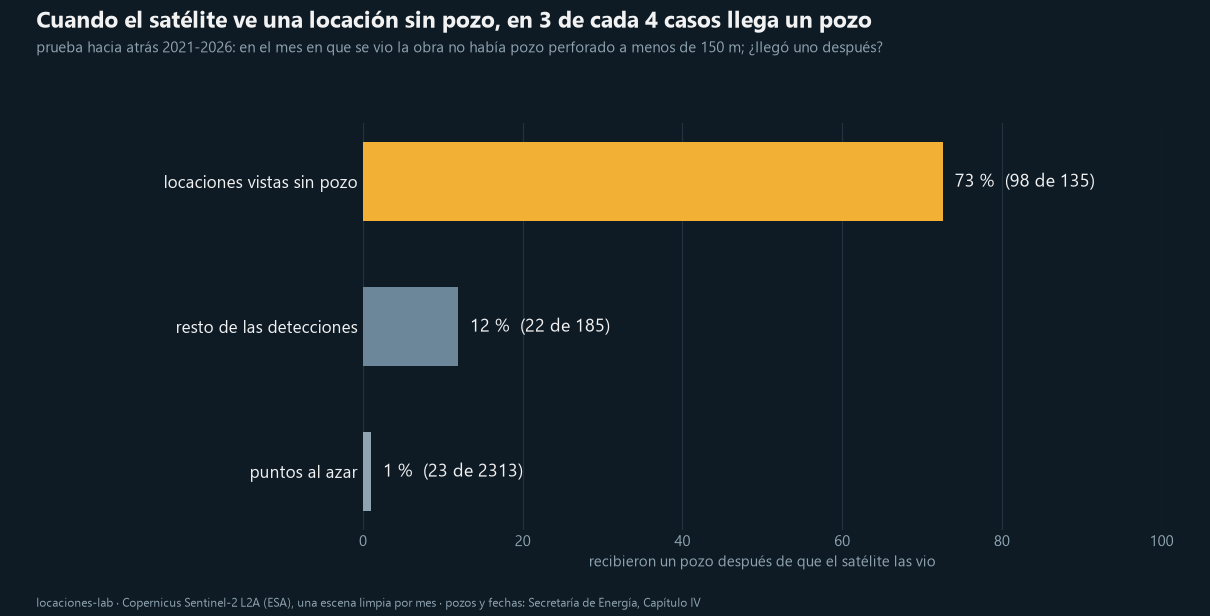

,grupo,porcentaje,detalle
0,locaciones vistas sin pozo,72.6,98 de 135
1,resto de las detecciones,11.9,22 de 185
2,puntos al azar,1.0,23 de 2313


In [4]:
px, py = TF.transform(POZ.lon.values, POZ.lat.values) if "POZ" in dir() else (None, None)
POZ = padron.pozos()
px, py = TF.transform(POZ.lon.values, POZ.lat.values)
perf = POZ.perforacion.values
dx, dy = TF.transform(D.lon.values, D.lat.values)
est = [ciego.estado_al_verla(x, yv, m, px, py, perf) for x, yv, m in zip(dx, dy, D.mes)]
D["estado"], D["espera_meses"] = [e[0] for e in est], [e[1] for e in est]
CORTE = pd.Timestamp("2026-10-01")
D["antiguedad"] = (CORTE - D.mes).dt.days / 30.4
rng = np.random.default_rng(3); base = []
for z, v in ZONAS.items():
    a, b, c, d_ = v["bbox"]
    lon, lat = rng.uniform(a, c, 600), rng.uniform(b, d_, 600)
    xx, yy = TF.transform(lon, lat)
    meses = pd.to_datetime(rng.choice(pd.date_range("2021-01-15", "2024-10-15", freq="MS").values, 600))
    base += [ciego.estado_al_verla(xi, yi, m, px, py, perf)[0] for xi, yi, m in zip(xx, yy, meses)]
base = pd.Series(base); base = base[base != "ya_perforado"]
filas = []
for nombre, X in (("locaciones vistas sin pozo", D[D.es_locacion]), ("resto de las detecciones", D[~D.es_locacion])):
    v = X[(X.estado != "ya_perforado") & (X.antiguedad >= 12)]
    filas.append({"grupo": nombre, "porcentaje": 100 * (v.estado == "llego_despues").mean(), "detalle": f"{(v.estado == 'llego_despues').sum()} de {len(v)}"})
filas.append({"grupo": "puntos al azar", "porcentaje": 100 * (base == "llego_despues").mean(), "detalle": f"{(base == 'llego_despues').sum()} de {len(base)}"})
T = pd.DataFrame(filas)
ll = D[D.es_locacion & (D.estado == "llego_despues")]
print(f"espera mediana entre la locación visible y el inicio de perforación: {ll.espera_meses.median():.1f} meses")
figuras.prueba_hacia_atras(T, FIGURES / "prueba_hacia_atras.png")
display(Image(FIGURES / "prueba_hacia_atras.png")); T.round(1)

## 4. La verificación: lo que el satélite ve y el padrón todavía no

Las locaciones vistas desde julio de 2025 que hoy no tienen ningún pozo registrado a menos de 150 m.
El padrón carga los pozos nuevos con unos seis meses de demora (en las cuatro ventanas, unos 50 pozos
por trimestre de inicio de perforación hasta comienzos de 2026 y 8 en el segundo trimestre), así que
la confirmación por el padrón llega a comienzos de 2027. Mientras tanto, cada una se miró en la escena
de septiembre-octubre de 2026. Las coordenadas quedan en `data/processed/` y no se publican.

In [5]:
print("pozos del shapefile en las ventanas por trimestre de inicio de perforación:")
en = POZ[POZ.apply(lambda r: any(v["bbox"][0] <= r.lon <= v["bbox"][2] and v["bbox"][1] <= r.lat <= v["bbox"][3] for v in ZONAS.values()), axis=1)]
print(en.perforacion.dt.to_period("Q").value_counts().sort_index().loc["2024Q1":].to_dict())
pred = D[D.es_locacion & (D.estado == "sin_pozo") & (D.mes >= "2025-07-01")]
pred.to_csv(DATA_PROC / "prediccion_locaciones_sin_pozo.csv", index=False)
V = pd.read_csv("../data/verificacion_visual_2026-10.csv")
print(f"\nlocaciones vistas desde 07/2025 sin pozo registrado: {len(pred)}")
V.verificacion_visual_oct2026.value_counts()

pozos del shapefile en las ventanas por trimestre de inicio de perforación:


{Period('2024Q1', 'Q-DEC'): 45, Period('2024Q2', 'Q-DEC'): 20, Period('2024Q3', 'Q-DEC'): 41, Period('2024Q4', 'Q-DEC'): 31, Period('2025Q1', 'Q-DEC'): 44, Period('2025Q2', 'Q-DEC'): 23, Period('2025Q3', 'Q-DEC'): 48, Period('2025Q4', 'Q-DEC'): 45, Period('2026Q1', 'Q-DEC'): 24, Period('2026Q2', 'Q-DEC'): 8}

locaciones vistas desde 07/2025 sin pozo registrado: 28


verificacion_visual_oct2026
con equipos trabajando                     12
locación construida, sin equipo todavía     8
falsa (pueblo, valle o barda)               5
instalación o locación con actividad        2
dudosa                                      1
Name: count, dtype: int64

22 de 28 son obras reales y 12 tienen hoy equipos en la locación, sin que figure un solo pozo en el
padrón público. La confirmación final: volver a bajar el padrón a comienzos de 2027 y contar cuántas
tienen pozo. Si la prueba hacia atrás vale, unas tres de cada cuatro.